<a href="https://colab.research.google.com/github/Nguza/AI-Project-Portfolio-/blob/main/Assignment_14_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Credit Card Fraud Detection

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [4]:
df = pd.read_csv('creditcard.csv')

Exploring the Dataset

In [5]:
eda_df = df.copy()

In [6]:
eda_df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0.0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0.0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0.0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0.0


Information about the Dataset

In [7]:
eda_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29799 entries, 0 to 29798
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    29799 non-null  int64  
 1   V1      29799 non-null  float64
 2   V2      29799 non-null  float64
 3   V3      29799 non-null  float64
 4   V4      29799 non-null  float64
 5   V5      29799 non-null  float64
 6   V6      29798 non-null  float64
 7   V7      29798 non-null  float64
 8   V8      29798 non-null  float64
 9   V9      29798 non-null  float64
 10  V10     29798 non-null  float64
 11  V11     29798 non-null  float64
 12  V12     29798 non-null  float64
 13  V13     29798 non-null  float64
 14  V14     29798 non-null  float64
 15  V15     29798 non-null  float64
 16  V16     29798 non-null  float64
 17  V17     29798 non-null  float64
 18  V18     29798 non-null  float64
 19  V19     29798 non-null  float64
 20  V20     29798 non-null  float64
 21  V21     29798 non-null  float64
 22

Balance of the Dataset

In [8]:
eda_df['Class'].value_counts()

,count
Class,
0.0,29704
1.0,94


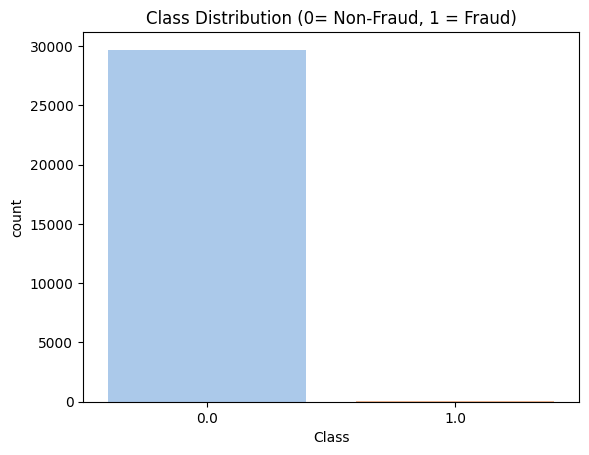

Class
0.0    99.684543
1.0     0.315457
Name: proportion, dtype: float64


In [10]:
# Count plot
sns.countplot(data=eda_df, x='Class', palette='pastel')
plt.title('Class Distribution (0= Non-Fraud, 1 = Fraud)')
plt.show()

#Percentage distribution
fraud_percent = df['Class'].value_counts(normalize=True)* 100
print(fraud_percent)

Missing Values

In [11]:
eda_df.isnull().sum()

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,1
V7,1
V8,1
V9,1


Chech for Duplicates

In [12]:
eda_df.duplicated().sum()

np.int64(121)

In [13]:
eda_df.drop_duplicates(inplace=True)

Check for Statistics

In [14]:
eda_df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,29678.000000,29678.000000,29678.000000,29678.000000,29678.000000,29678.000000,29677.000000,29677.000000,29677.000000,29677.000000,...,29677.000000,29677.000000,29677.000000,29677.000000,29677.000000,29677.000000,29677.000000,29677.000000,29677.000000,29677.000000
mean,21415.387492,-0.207287,0.122611,0.720453,0.210962,-0.203390,0.086943,-0.120732,0.031736,0.349420,...,-0.035616,-0.122747,-0.042132,0.009399,0.132286,0.023575,0.013887,0.005191,79.811195,0.003167
std,12030.814542,1.845087,1.543908,1.615868,1.420244,1.420899,1.321608,1.292389,1.282120,1.257851,...,0.778129,0.639813,0.541368,0.591927,0.435850,0.511345,0.382686,0.273409,222.466014,0.056192
min,0.000000,-30.552380,-40.978852,-31.103685,-5.172595,-42.147898,-23.496714,-26.548144,-41.484823,-7.175097,...,-20.262054,-8.593642,-26.751119,-2.836627,-7.495741,-1.338556,-8.567638,-9.617915,0.000000,0.000000
25%,10137.500000,-0.948244,-0.448870,0.262172,-0.699779,-0.798279,-0.655624,-0.594427,-0.160211,-0.459426,...,-0.244952,-0.545954,-0.176389,-0.326904,-0.130435,-0.333734,-0.063340,-0.007898,6.580000,0.000000
50%,26169.000000,-0.248095,0.148444,0.845388,0.193831,-0.236499,-0.173493,-0.067956,0.035351,0.242617,...,-0.090635,-0.096194,-0.050318,0.062238,0.171671,-0.056380,0.008232,0.020446,20.000000,0.000000
75%,32190.000000,1.165967,0.784632,1.473957,1.093566,0.312941,0.472825,0.445003,0.292860,1.106746,...,0.083621,0.285619,0.075088,0.398624,0.415039,0.304383,0.089781,0.076664,71.070000,0.000000
max,35634.000000,1.960497,16.713389,4.101716,13.143668,34.099309,22.529298,36.677268,20.007208,10.392889,...,22.614889,5.805795,13.876221,4.014444,5.525093,3.517346,11.135740,4.860769,7879.420000,1.000000


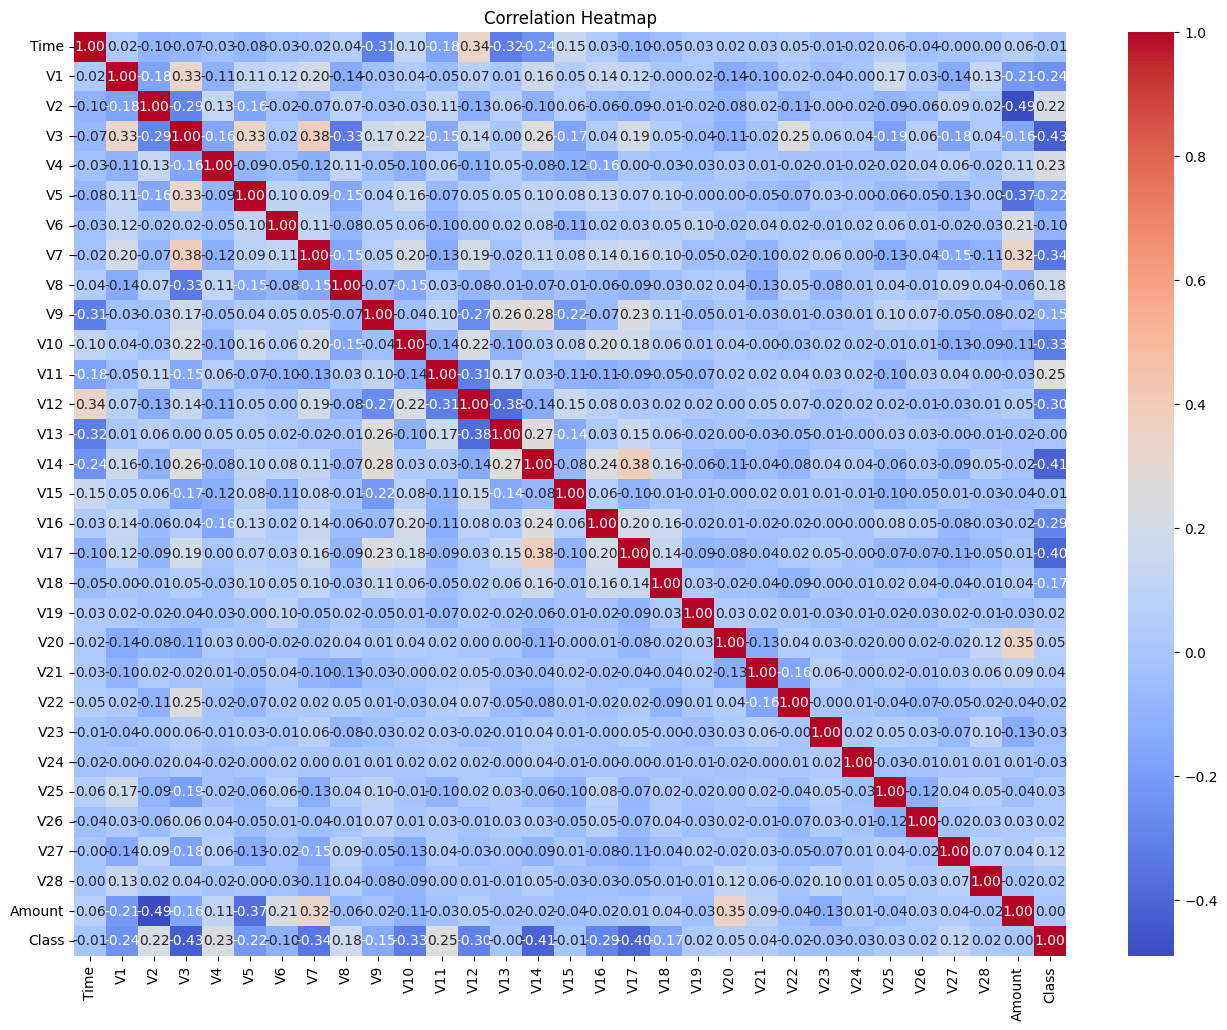

In [15]:
# Correlation heatmap
plt.figure(figsize=(16, 12))
sns.heatmap(eda_df.corr(), cmap='coolwarm', annot=True, fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

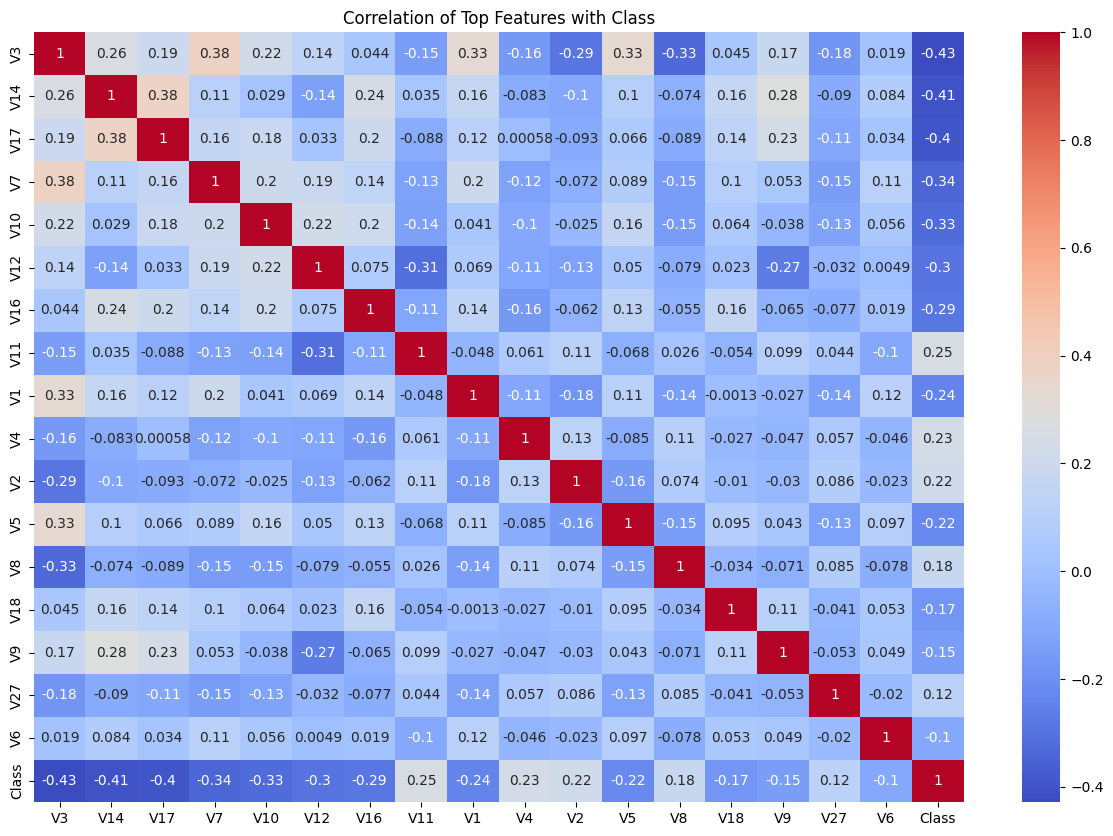

In [16]:
# Top 10 features correlated with fraud
top_corr = eda_df.corr()['Class'].abs().sort_values(ascending=False)[1:18].index.tolist()

plt.figure(figsize=(15, 10))
sns.heatmap(eda_df[top_corr + ['Class']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation of Top Features with Class')
plt.show()

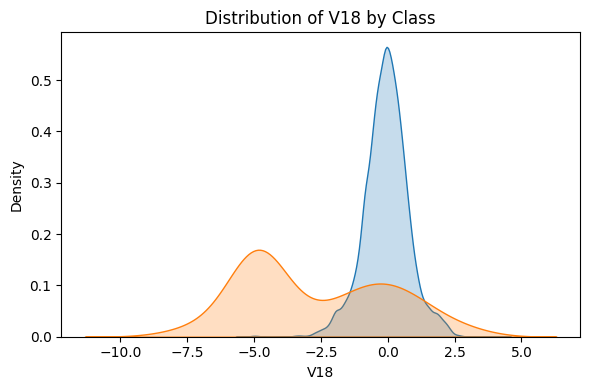

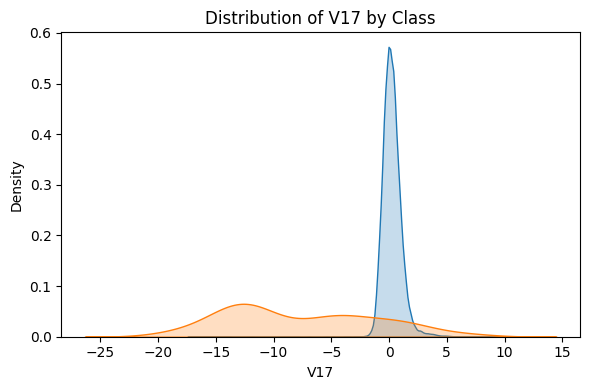

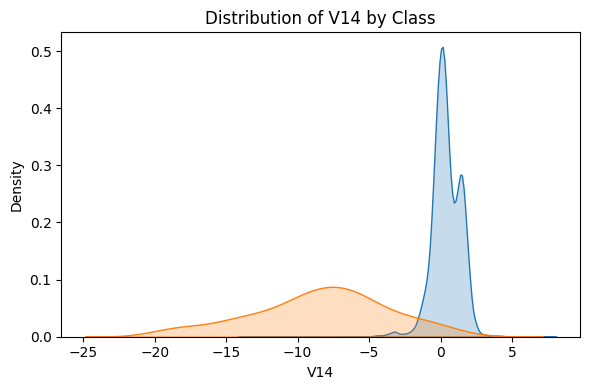

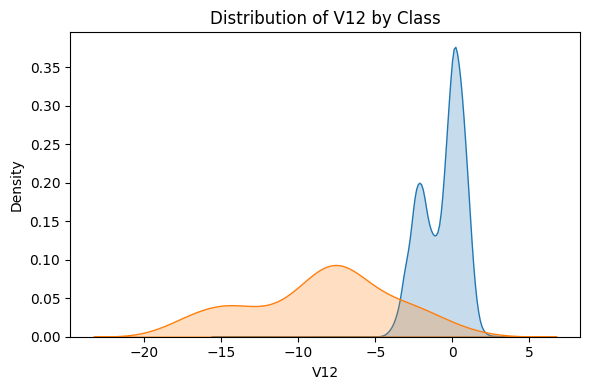

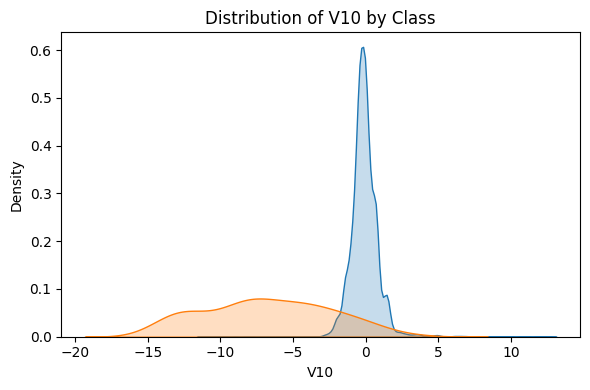

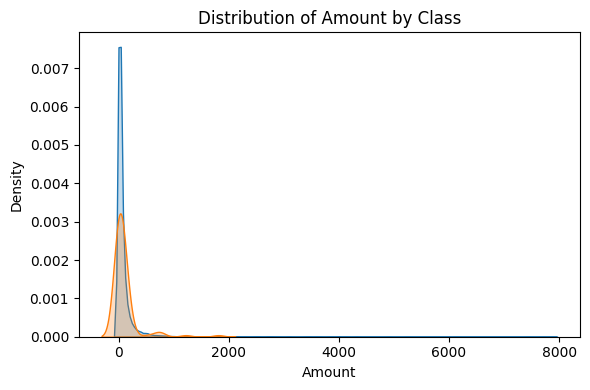

In [21]:
# Visualize distribution of top correlated features
important_features = ['V18', 'V17', 'V14', 'V12', 'V10', 'Amount']

for col in important_features:
    plt.figure(figsize=(6, 4))
    sns.kdeplot(data=eda_df[eda_df['Class'] == 0], x=col, label='Non-Fraud', fill=True)
    sns.kdeplot(data=eda_df[eda_df['Class'] == 1], x=col, label='Fraud', fill=True)
    plt.title(f'Distribution of {col} by Class')
    plt.legend
    plt.tight_layout()
    plt.show()

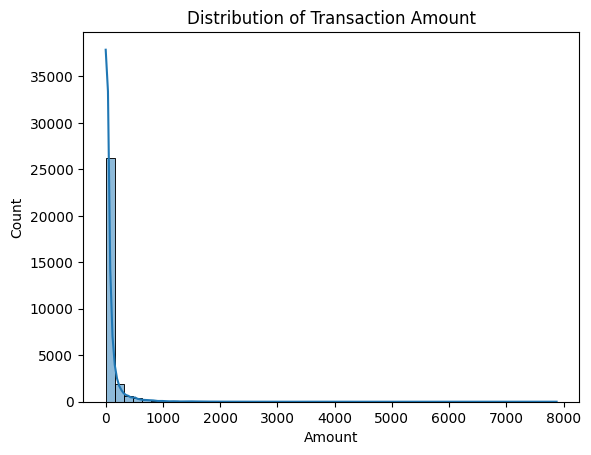

In [22]:
# Distribution of Amount
sns.histplot(eda_df['Amount'], bins=50, kde=True)
plt.title('Distribution of Transaction Amount')
plt.show()

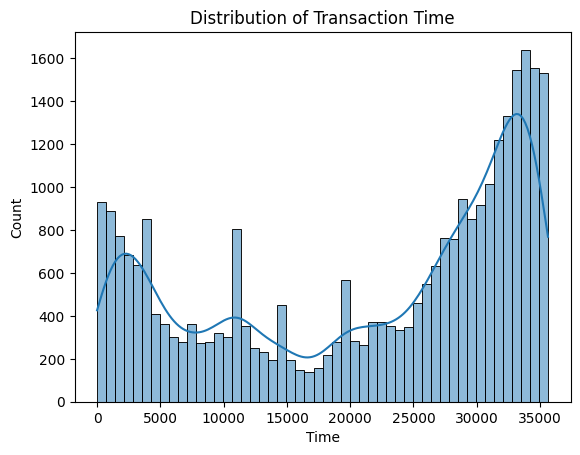

In [23]:
# Distibution of Time
sns.histplot(eda_df['Time'], bins=50, kde=True)
plt.title('Distribution of Transaction Time')
plt.show()

Comparing Fraud vs Non-Fraud

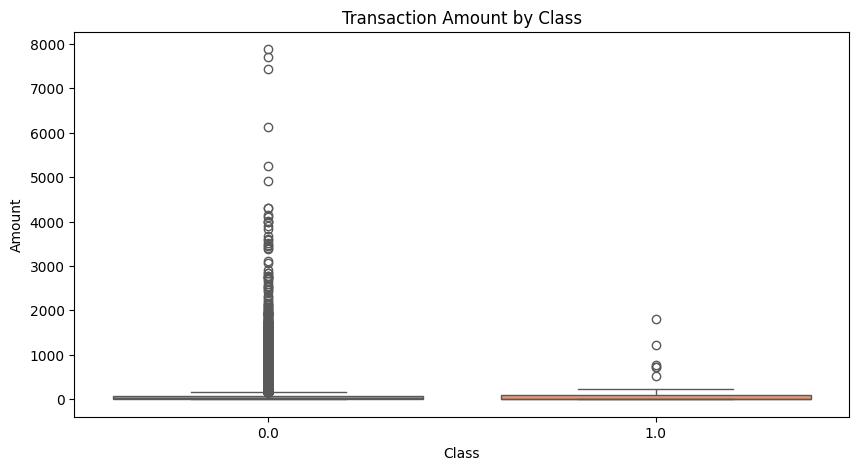

In [24]:
# Grouped by Class for Amount
plt.figure(figsize=(10, 5))
sns.boxplot(x='Class', y='Amount', data=eda_df, palette='Set2')
plt.title('Transaction Amount by Class')
plt.show()

Correlation Analysis

In [25]:
correlation_with_class = eda_df.corr()['Class'].drop('Class').sort_values(ascending=False)
print(correlation_with_class)

V11       0.252501
V4        0.230329
V2        0.217691
V8        0.176394
V27       0.120307
V20       0.054292
V21       0.044161
V25       0.028474
V19       0.023435
V28       0.019764
V26       0.017595
Amount    0.003998
V13      -0.002158
V15      -0.008534
Time     -0.011279
V22      -0.022744
V24      -0.025484
V23      -0.030886
V6       -0.104810
V9       -0.145237
V18      -0.172673
V5       -0.217348
V1       -0.241123
V16      -0.287761
V12      -0.299468
V10      -0.325246
V7       -0.339841
V17      -0.399764
V14      -0.405120
V3       -0.428609
Name: Class, dtype: float64


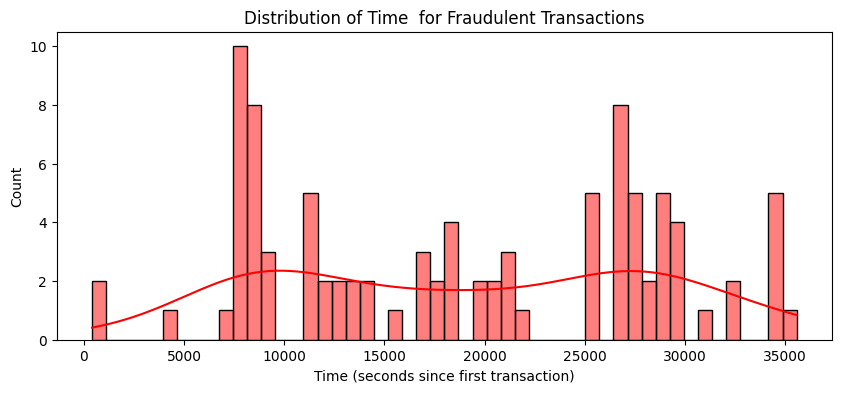

In [26]:
plt.figure(figsize=(10, 4))
sns.histplot(eda_df[eda_df['Class'] == 1]['Time'], bins=50, color='red', kde=True)
plt.title('Distribution of Time  for Fraudulent Transactions')
plt.xlabel('Time (seconds since first transaction)')
plt.show()

DataSet for Modeling

In [27]:
eda_df.isna().sum()

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,1
V7,1
V8,1
V9,1


In [28]:
eda_df.dropna(inplace=True)

In [29]:
from sklearn.model_selection import train_test_split

X = eda_df.drop('Class', axis=1)
y = eda_df['Class']

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)


In [31]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_train, y_train)


In [32]:
y_resampled.value_counts()


,count
Class,
0.0,23666
1.0,23666


In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve
from xgboost import XGBClassifier


In [48]:
 # Define numeric columns
numeric_features = X.columns.tolist()

# Preprocessing step
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features)
    ]
)

# Build pipeline
random_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))
])

# Fit the pipeline
random_pipeline.fit(X_resampled, y_resampled)

# Predict
random_pred = random_pipeline.predict(X_test)
rm_y_proba = random_pipeline.predict_proba(X_test)[:, 1]

# Evaluation
print("Confusion Matrix:\n", confusion_matrix(y_test, random_pred))
print("\nClassification Report:\n", classification_report(y_test, random_pred))
print("\nROC AUC Score:", roc_auc_score(y_test, rm_y_proba))

Confusion Matrix:
 [[5914    3]
 [   3   16]]

Classification Report:
               precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      5917
         1.0       0.84      0.84      0.84        19

    accuracy                           1.00      5936
   macro avg       0.92      0.92      0.92      5936
weighted avg       1.00      1.00      1.00      5936


ROC AUC Score: 0.9965932238065165


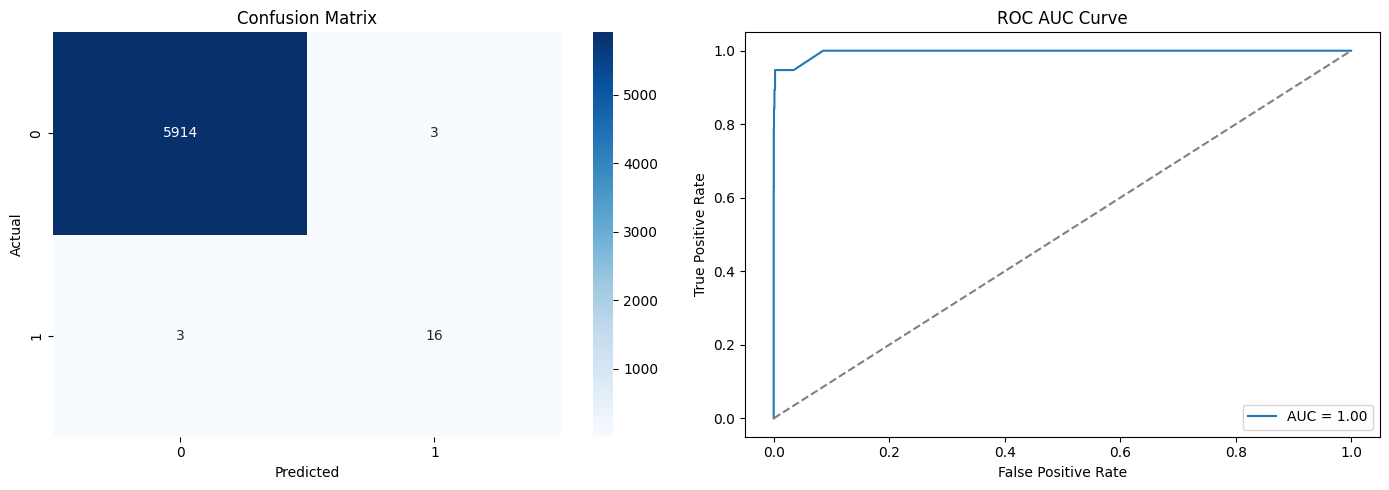

In [49]:
# Confusion matrix
random_cm = confusion_matrix(y_test, random_pred)

# ROC curve
fpr, tpr, thresholds = roc_curve(y_test, rm_y_proba)
roc_auc = roc_auc_score(y_test, rm_y_proba)

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion matrix plot
sns.heatmap(random_cm, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# ROC AUC curve plot
axes[1].plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}')
axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray')
axes[1].set_title('ROC AUC Curve')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend()

plt.tight_layout()
plt.show()

In [50]:
#print the best threshold value

j_scores = tpr - fpr
best_index = np.argmax(j_scores)
best_threshold = thresholds[best_index]

print(f"Best Threshold: {best_threshold:.3f}")

Best Threshold: 0.110


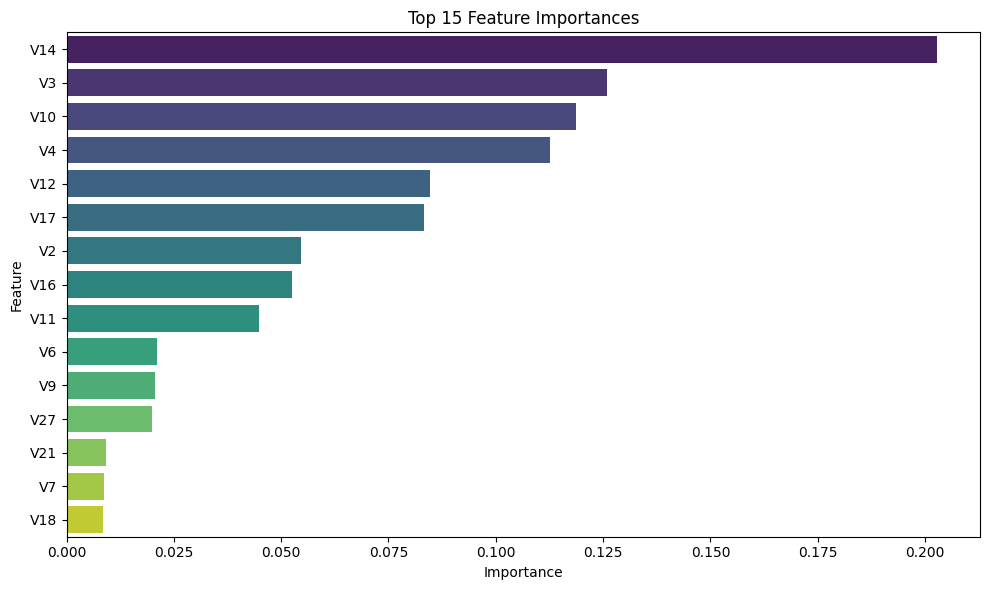

In [51]:
# Get feature importances from the trained model
random_model = random_pipeline.named_steps['classifier']
importances = random_model.feature_importances_

# Get feature names (same as original features)
feature_names = X.columns

# Create a DataFrame for plotting
feat_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feat_imp_df.head(15), palette='viridis')
plt.title('Top 15 Feature Importances')
plt.tight_layout()
plt.show()

Confusion Matrix:
 [[5913    4]
 [   3   16]]

Classification Report:
               precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      5917
         1.0       0.80      0.84      0.82        19

    accuracy                           1.00      5936
   macro avg       0.90      0.92      0.91      5936
weighted avg       1.00      1.00      1.00      5936


ROC AUC Score: 0.9976339361162752


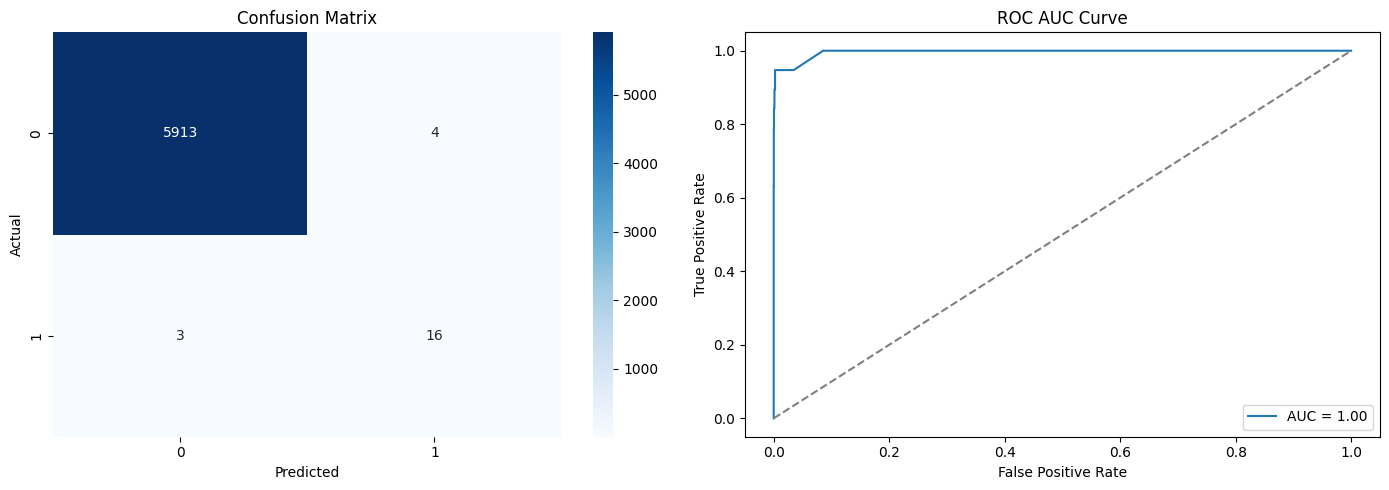

In [52]:
# Create pipeline with XGBoost
xgboost_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42))
])

# Train the pipeline
xgboost_pipeline.fit(X_resampled, y_resampled)

# Predictions
xg_pred = xgboost_pipeline.predict(X_test)
xg_y_proba = xgboost_pipeline.predict_proba(X_test)[:, 1]

# Evaluation
print("Confusion Matrix:\n", confusion_matrix(y_test, xg_pred))
print("\nClassification Report:\n", classification_report(y_test, xg_pred))
print("\nROC AUC Score:", roc_auc_score(y_test, xg_y_proba))

xg_cm =  confusion_matrix(y_test, xg_pred)

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion matrix plot
sns.heatmap(xg_cm, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# ROC AUC curve plot
axes[1].plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}')
axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray')
axes[1].set_title('ROC AUC Curve')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend()
plt.tight_layout()
plt.show()

<Figure size 1200x600 with 0 Axes>

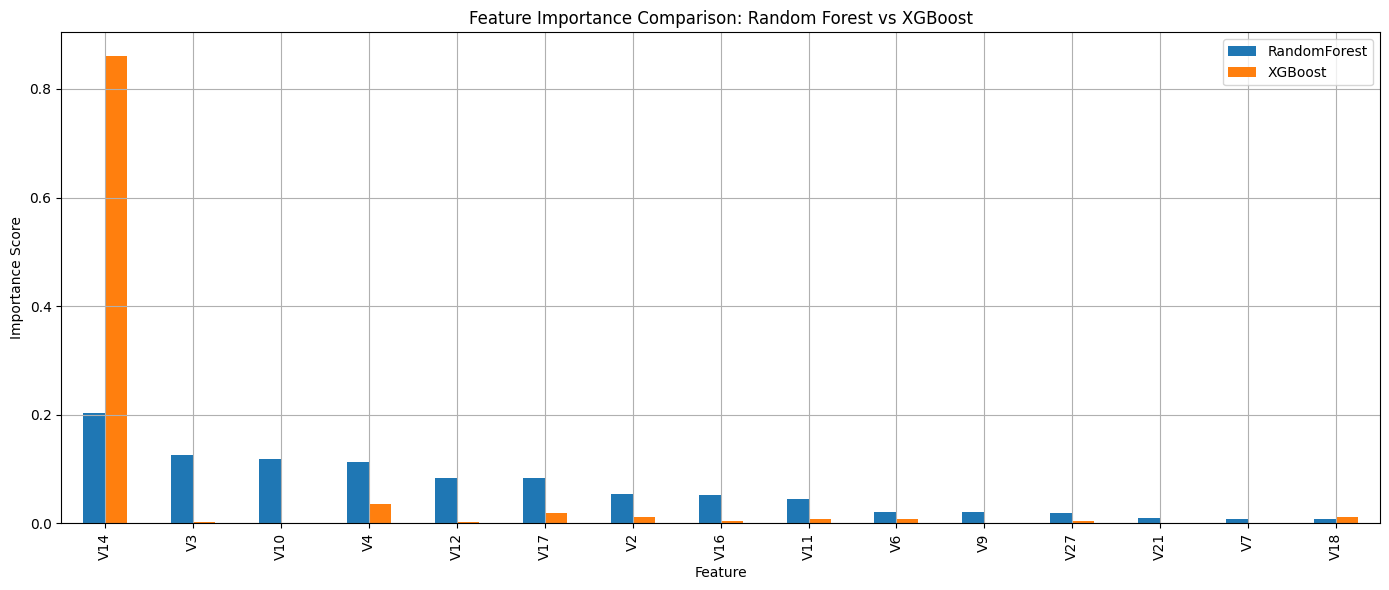

In [53]:
# Get feature importances
rf_importances = random_pipeline.named_steps['classifier'].feature_importances_
xgb_importances = xgboost_pipeline.named_steps['classifier'].feature_importances_
features = X.columns

# Create DataFrame for comparison
importance_df = pd.DataFrame({
    'Feature': features,
    'RandomForest': rf_importances,
    'XGBoost': xgb_importances
}).set_index('Feature')

# Plot comparison
plt.figure(figsize=(12, 6))
importance_df.sort_values(by='RandomForest', ascending=False).head(15).plot(kind='bar', figsize=(14, 6))
plt.title('Feature Importance Comparison: Random Forest vs XGBoost')
plt.ylabel('Importance Score')
plt.grid(True)
plt.tight_layout()
plt.show()

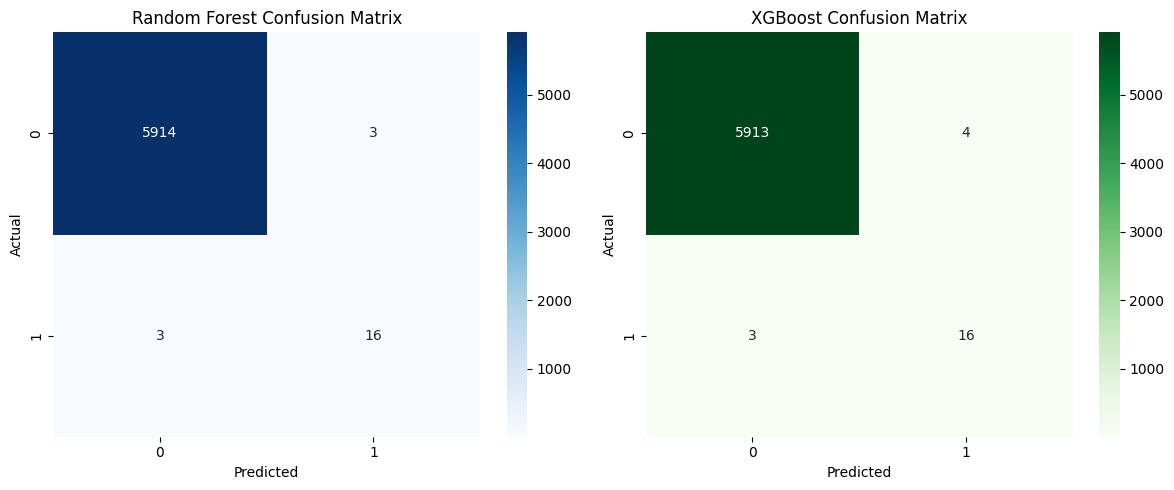

In [54]:
# Confusion matrices
rf_cm = confusion_matrix(y_test, random_pred)
xgb_cm = confusion_matrix(y_test, xg_pred)

# Plot confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(rf_cm, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title("Random Forest Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(xgb_cm, annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title("XGBoost Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()